# jPCA on the real Churchland et al. 2012 data

This notebook runs **our own pipeline** (`jpca_core.py`) on the actual data distributed
with the original jPCA code release (`exampleData.mat`, Churchland lab website;
mirrored in the nwb4edu repo). Everything in Notebooks 1–2 is synthetic; this is the
real thing.

**What the data is** (from the 2012 paper): M1/PMd **array** recordings during the
"maze task" — straight reaches and reaches curved around barriers. 108 conditions
(4 sets of 27 target/barrier arrangements), 218 units, firing rates sampled every
10 ms starting 50 ms before movement onset. With 218 units it matches the paper's
"N-array" dataset (monkey N; Figure 3f) — J-array had 146 isolations. Note: this is
the *maze* task data — the 8-target center-out sets are different datasets (see
README for links); the straight reaches are a subset of the 108 conditions here.

The data is already distributed as smoothed firing rates, so we skip the smoothing
step of `preprocess` and keep only soft-normalization + cross-condition mean subtraction.

108 conditions | 218 neurons | 61 time points
time axis (ms): -50 ... 550 step 10


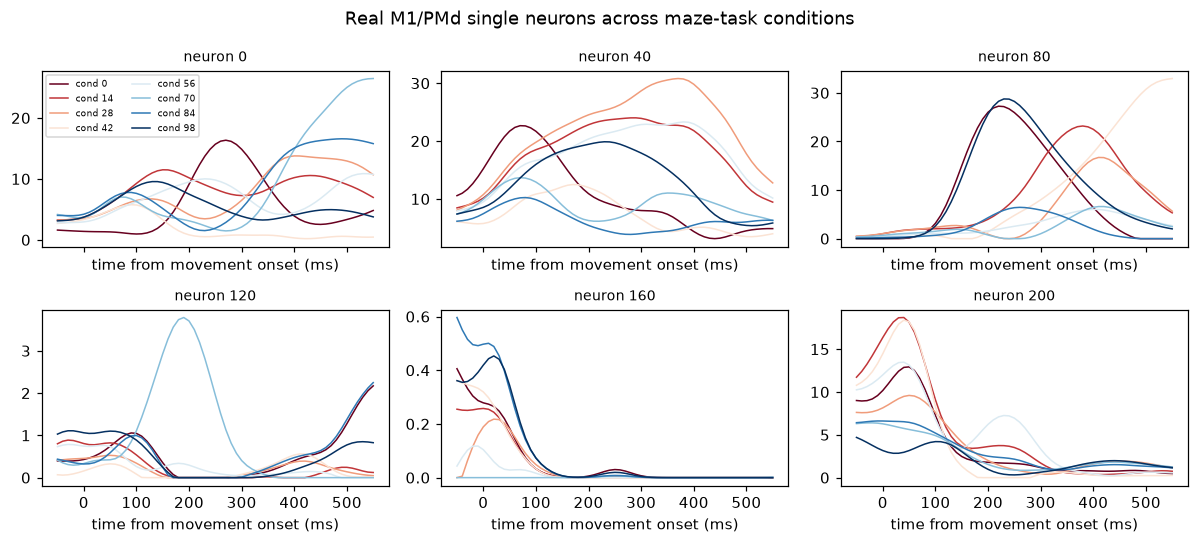

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from jpca_core import *
%matplotlib inline
plt.rcParams['figure.dpi'] = 110

# --- Load the real data (scipy only; the .mat predates v7.3) ----------------
from scipy.io import loadmat

# squeeze_me collapses the (1, 108) struct array to a plain (108,) record
# array; all conditions share one time axis, so the whole dataset stacks in
# a single call -- no per-condition loop.
Data = loadmat('data/exampleData.mat', squeeze_me=True)['Data']  # fields: A, times
rates_ctn = np.stack(Data['A'])                   # (C, T, N) = (108, 61, 218)
times = np.asarray(Data[0]['times']).ravel()      # time axis in ms (taken from condition 0)
for c in range(Data.size):                        # check that every condition uses this same axis
    assert np.array_equal(np.asarray(Data[c]['times']).ravel(), times)

C, T, N = rates_ctn.shape
rates_real = rates_ctn.transpose(2, 0, 1)   # reorder to (N, C, T) -- like MATLAB permute(x, [3 1 2])
print(f'{C} conditions | {N} neurons | {T} time points')
print('time axis (ms):', times[0], '...', times[-1], 'step', times[1]-times[0])

# --- nwb4edu-style exploration: example neurons across conditions ----------
# (colors here only distinguish conditions; the state-space figures below use
# the paper's convention: color = sorted starting jPC1, i.e. preparatory state)
neurons_to_show = [0, 40, 80, 120, 160, 200]      # 6 example neurons, one per panel
conds_to_show = list(range(0, C, 14))             # every 14th condition -> 8 conditions

fig, axes = plt.subplots(2, 3, figsize=(11, 5), sharex=True)   # grid of 2 rows x 3 columns
for panel in range(6):
    ax = axes[panel // 3, panel % 3]              # panel 0..5 -> its (row, col) in the grid
    neuron = neurons_to_show[panel]
    for k in range(len(conds_to_show)):
        cond = conds_to_show[k]
        # color from the blue->red colormap: 0.0 = blue (first condition), 1.0 = red (last)
        color = plt.cm.RdBu(k / (len(conds_to_show) - 1))
        ax.plot(times, rates_real[neuron, cond, :], color=color, linewidth=1)
    ax.set_title(f'neuron {neuron}', fontsize=9)
    ax.set_xlabel('time from movement onset (ms)')

legend_labels = []
for cond in conds_to_show:
    legend_labels.append(f'cond {cond}')
axes[0, 0].legend(legend_labels, fontsize=6, ncol=2)
fig.suptitle('Real M1/PMd single neurons across maze-task conditions')
fig.tight_layout(); plt.show()

**The peak-time-sorted raster, on real data.** Before any jPCA: average each neuron
across all 108 conditions, sort neurons by their peak time, and look at one condition.
The "traveling wave" appears — this is exactly the Kuzmina et al. construction, on the
very dataset Churchland analyzed. Keep this circularity in mind when the rotation
appears below (Notebook 2 unpacks it).

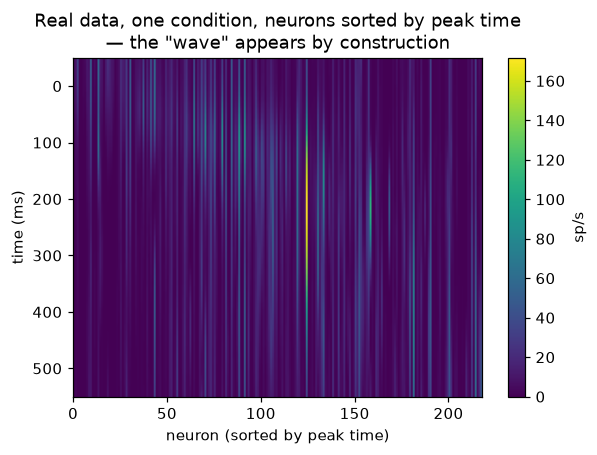

In [2]:
mean_rates = rates_real.mean(axis=1)                      # (N, T) across conditions
peak_order = np.argsort(np.argmax(mean_rates, axis=1))
plt.figure(figsize=(6, 4))
plt.imshow(rates_real[peak_order][:, 10].T, aspect='auto', cmap='viridis',
           extent=[0, N, times[-1], times[0]])
plt.xlabel('neuron (sorted by peak time)'); plt.ylabel('time (ms)')
plt.title('Real data, one condition, neurons sorted by peak time\n— the "wave" appears by construction')
plt.colorbar(label='sp/s'); plt.show()

**Preprocessing on the real data, before → after.** Same steps as Notebook 1,
except the smoothing step is skipped (`smooth_sd_ms=0`): this file already contains
smoothed firing rates. Watch the two active steps — soft-normalization and
condition-mean subtraction — on the most strongly modulated unit and a
quiet-but-responsive one (10th percentile of range):

per-unit range before normalization: 0.2 .. 170.1 sp/s
unit 206: range 170.1 sp/s  ->  0.97 after normalization
unit 21: range 6.6 sp/s  ->  0.57 after normalization
the +5 sp/s "soft" constant: without it unit 21 would be scaled up 25.9x more than unit 206; with it, only 15.1x


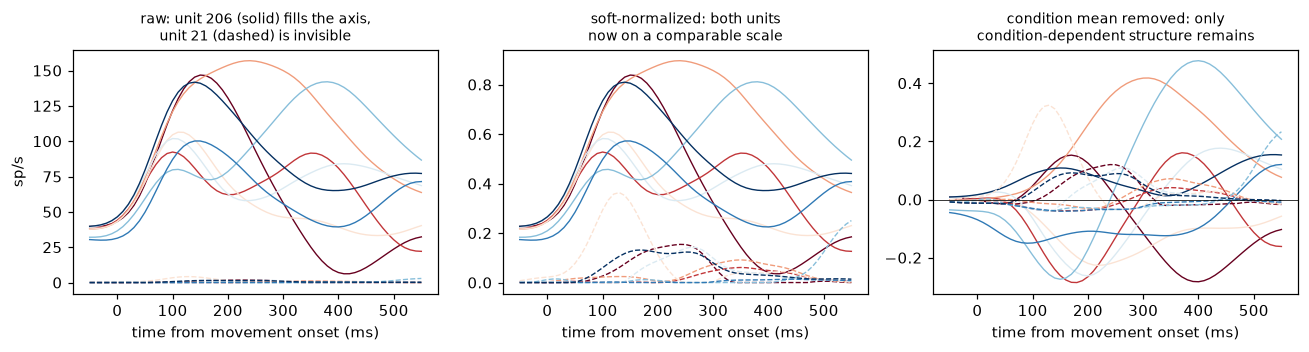

check: step-by-step == preprocess(): True


In [3]:
# --- What the preprocessing does to the real data, before -> after ----------
spread = rates_real.max(axis=(1, 2)) - rates_real.min(axis=(1, 2))     # per-unit range
normed = rates_real / (spread + 5.0)[:, None, None]                    # 2. soft-normalize
final = normed - normed.mean(axis=1, keepdims=True)                    # 3. subtract condition mean

hi = int(np.argmax(spread))                       # most modulated unit
lo = int(np.argsort(spread)[len(spread) // 10])   # 10th percentile: quiet but responsive
print(f'per-unit range before normalization: {spread.min():.1f} .. {spread.max():.1f} sp/s')
print(f'unit {hi}: range {spread[hi]:.1f} sp/s  ->  {np.ptp(normed[hi]):.2f} after normalization')
print(f'unit {lo}: range {spread[lo]:.1f} sp/s  ->  {np.ptp(normed[lo]):.2f} after normalization')
print(f'the +5 sp/s "soft" constant: without it unit {lo} would be scaled up '
      f'{spread[hi] / spread[lo]:.1f}x more than unit {hi}; with it, only '
      f'{(spread[hi] + 5) / (spread[lo] + 5):.1f}x')

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for u, ls in [(hi, '-'), (lo, '--')]:
    for k, cond in enumerate(conds_to_show):
        color = plt.cm.RdBu(k / (len(conds_to_show) - 1))   # same conditions as above
        axes[0].plot(times, rates_real[u, cond], color=color, lw=0.9, ls=ls)
        axes[1].plot(times, normed[u, cond], color=color, lw=0.9, ls=ls)
        axes[2].plot(times, final[u, cond], color=color, lw=0.9, ls=ls)
axes[0].set_title(f'raw: unit {hi} (solid) fills the axis,\nunit {lo} (dashed) is invisible',
                  fontsize=9)
axes[1].set_title('soft-normalized: both units\nnow on a comparable scale', fontsize=9)
axes[2].axhline(0, color='k', lw=0.5)
axes[2].set_title('condition mean removed: only\ncondition-dependent structure remains',
                  fontsize=9)
for ax in axes:
    ax.set_xlabel('time from movement onset (ms)')
axes[0].set_ylabel('sp/s')
fig.tight_layout(); plt.show()

rates_p = preprocess(rates_real, bin_ms=10, smooth_sd_ms=0)   # one call, already smoothed
print('check: step-by-step == preprocess():', np.allclose(final, rates_p))

**jPCA on the real data, step by step.** The same treatment for the analysis itself:
instead of calling `jpca()` as a black box, the next cell spells out each step —
stack conditions → PCA to 6 dimensions → fit linear dynamics `dZ = M·Z` with `M`
restricted to be skew-symmetric (rotation only) → read the rotation planes and their
frequencies off the eigenvalues of `M` → align the axes within each plane. It collects
the results in `res_steps`, laid out like the dictionary `jpca()` returns; the cell after
it runs the one-line `jpca()` and compares the two side by side.

In [4]:
# --- jPCA step by step: what the one-line jpca() call does internally -------
from sklearn.decomposition import PCA
from scipy.optimize import minimize

n_pcs, dt_s = 6, 0.01                             # 6 PCs -> 3 planes; 10 ms bins

# 1. Stack conditions end to end: every (condition, time) pair is one sample.
X = rates_p.reshape(N, C * T)                     # (N, C*T)

# 2. PCA down to the top 6 PCs. Z is the population state in PC space; jPCA
#    never leaves this 6-D space, it only picks new axes inside it.
pca = PCA(n_components=n_pcs)
Z = pca.fit_transform(X.T).T                      # (6, C*T)
print('1-2. PCA: %d neurons -> %d PCs holding %.0f%% of the variance'
      % (N, n_pcs, 100 * pca.explained_variance_ratio_.sum()))

# 3. State and its change over one time step. (As in jpca(), the difference
#    runs along the stacked axis, so it also includes the C-1 jumps from the
#    end of one condition to the start of the next.)
Z0 = Z[:, :-1]                                    # state now
dZ = np.diff(Z, axis=1)                           # state next - state now

# 4. Fit linear dynamics dZ = M Z0, twice.
#    a) unconstrained least squares: M_full may stretch, shrink and rotate
M_full = np.linalg.lstsq(Z0.T, dZ.T, rcond=None)[0].T
r2_full = 1.0 - np.sum((dZ - M_full @ Z0) ** 2) / np.sum(dZ ** 2)
#    b) skew-symmetric only (M = -M^T): such a matrix can only rotate.
#       (M_full - M_full^T)/2 is the closed-form starting guess; conjugate
#       gradients then finds the best skew-symmetric M. Only the entries above
#       the diagonal are free (15 numbers for 6x6), so we optimize those.
iu = np.triu_indices(n_pcs, k=1)

def vec2mat(h):                                   # 15 numbers -> 6x6 skew matrix
    M = np.zeros((n_pcs, n_pcs))
    M[iu] = h
    return M - M.T

def objective(h):                                 # squared error of dZ = M Z0
    return 0.5 * np.sum((Z0.T @ vec2mat(h).T - dZ.T) ** 2)

def gradient(h):
    dM = (Z0 @ Z0.T @ vec2mat(h).T) - (Z0 @ dZ.T)
    return (dM.T - dM)[iu]

M_start = 0.5 * (M_full - M_full.T)
fit = minimize(objective, M_start[iu], jac=gradient, method='CG',
               options=dict(maxiter=10000, gtol=1e-4))
M_skew = vec2mat(fit.x)

# 5. How much of the dynamics does pure rotation explain?
r2 = 1.0 - np.sum((dZ - M_skew @ Z0) ** 2) / np.sum(dZ ** 2)
print('4-5. fit R^2: any linear dynamics %.3f | rotation only %.3f' % (r2_full, r2))

# 6. Eigen-decomposition. A skew-symmetric matrix has purely imaginary
#    eigenvalues in conjugate pairs +-i*w: each pair is one rotation plane and
#    w is its angular speed (radians per bin). The real and imaginary parts of
#    the eigenvector span the plane; QR makes them an orthonormal 2-D basis.
eigvals, eigvecs = np.linalg.eig(M_skew)
print('6.   eigenvalues (imaginary part):', np.round(np.sort(eigvals.imag), 4))
planes, freqs_hz = [], []
for i in np.argsort(-eigvals.imag):               # fastest rotation first
    if eigvals[i].imag <= 1e-10:
        break                                     # the rest are the -i*w partners
    v = eigvecs[:, i]
    Q, _ = np.linalg.qr(np.column_stack([v.real, v.imag]))
    planes.append(Q)                              # (6, 2): PC space -> this plane
    freqs_hz.append(eigvals[i].imag / (2 * np.pi * dt_s))   # rad/bin -> Hz

# 7. Display convention: the two axes inside a plane are arbitrary up to a
#    rotation, so turn them until the starting (first-bin, preparatory) states
#    spread along jPC1. Pure in-plane rotation: nothing about the fit changes.
Zc = Z.reshape(n_pcs, C, T)
for k, Q in enumerate(planes):
    coords = np.einsum('ij,jct->ict', Q.T, Zc)    # (2, C, T) in-plane trajectories
    start = coords[:, :, 0].T                     # (C, 2) starting states
    rot = PCA(n_components=2).fit(start).components_
    if np.linalg.det(rot) < 0:                    # keep the basis right-handed
        rot[1] = -rot[1]
    new = np.einsum('ij,jct->ict', rot, coords)
    if np.abs(new[1]).max() > new[1].max():       # largest jPC2 excursion positive
        rot = -rot
    planes[k] = Q @ rot.T

# Same dict layout that jpca() returns; compared with the one-line call below.
res_steps = dict(pca=pca, Z=Z, M_skew=M_skew, r2=r2, eigvals=eigvals,
                 planes=planes, freqs_hz=freqs_hz, n_conditions=C, dt_s=dt_s)
print('7.   rotation frequencies (Hz):', np.round(freqs_hz, 2))

1-2. PCA: 218 neurons -> 6 PCs holding 48% of the variance
4-5. fit R^2: any linear dynamics 0.165 | rotation only 0.146
6.   eigenvalues (imaginary part): [-0.0781 -0.0326 -0.0024  0.0024  0.0326  0.0781]
7.   rotation frequencies (Hz): [1.24 0.52 0.04]


                                   step-by-step     jpca()
whole-space rotation R^2                 0.1455     0.1455
rotation frequency 1 (Hz)                 1.242      1.242
rotation frequency 2 (Hz)                 0.518      0.518
rotation frequency 3 (Hz)                 0.038      0.038
jPC plane 1: % of variance                 39.5       39.5
jPC plane 1: in-plane R^2                 0.073      0.073
jPC plane 2: % of variance                 31.9       31.9
jPC plane 2: in-plane R^2                 0.376      0.376
jPC plane 3: % of variance                 28.7       28.7
jPC plane 3: in-plane R^2                 0.000      0.000
largest difference in M_skew: 1.5e-14
largest difference in plane axes: 2.8e-13
check: step-by-step == jpca(): True


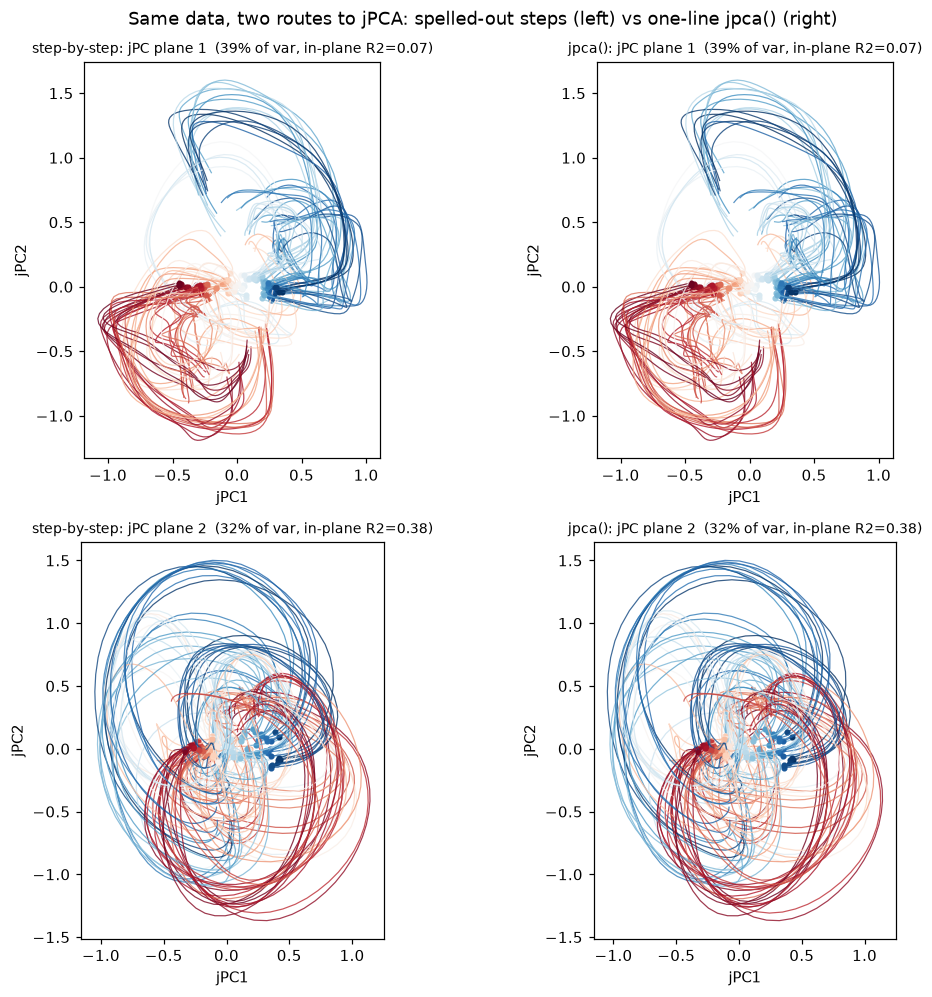

In [5]:
# --- Compact jpca() vs the step-by-step version, side by side ---------------
res = jpca(rates_p, n_pcs=6, dt_s=0.01)   # default: original-toolbox fit + axis alignment

projs_steps = project_planes(res_steps)           # planes ordered by variance
projs_compact = project_planes(res)

print('%-32s %14s %10s' % ('', 'step-by-step', 'jpca()'))
print('%-32s %14.4f %10.4f' % ('whole-space rotation R^2', res_steps['r2'], res['r2']))
for k in range(len(res['freqs_hz'])):
    print('%-32s %14.3f %10.3f' % (f'rotation frequency {k + 1} (Hz)',
                                   res_steps['freqs_hz'][k], res['freqs_hz'][k]))
for k in range(len(projs_compact)):
    print('%-32s %14.1f %10.1f' % (f'jPC plane {k + 1}: % of variance',
                                   100 * projs_steps[k][1], 100 * projs_compact[k][1]))
    print('%-32s %14.3f %10.3f' % (f'jPC plane {k + 1}: in-plane R^2',
                                   projs_steps[k][2], projs_compact[k][2]))
print('largest difference in M_skew: %.1e' % np.abs(res_steps['M_skew'] - res['M_skew']).max())
print('largest difference in plane axes: %.1e'
      % max(np.abs(P - Pr).max() for P, Pr in zip(res_steps['planes'], res['planes'])))
print('check: step-by-step == jpca():',
      np.allclose(res_steps['M_skew'], res['M_skew']) and np.isclose(res_steps['r2'], res['r2'])
      and all(np.allclose(P, Pr) for P, Pr in zip(res_steps['planes'], res['planes'])))

# left column: step-by-step, right column: jpca(); one row per jPC plane
fig, axes = plt.subplots(2, 2, figsize=(10, 9.2))
for col, (name, projs_m) in enumerate([('step-by-step', projs_steps), ('jpca()', projs_compact)]):
    for row in range(2):
        coords, frac, r2p = projs_m[row]
        cols_k = start_ordered_colors(coords)      # color = starting jPC1 (preparatory)
        ax = axes[row, col]
        for c in range(C):
            ax.plot(coords[0, c], coords[1, c], color=cols_k[c], lw=0.8, alpha=0.8)
            ax.plot(coords[0, c, 0], coords[1, c, 0], 'o', color=cols_k[c], ms=3)
        ax.set_title(f'{name}: jPC plane {row + 1}  ({frac:.0%} of var, in-plane R2={r2p:.2f})',
                     fontsize=9)
        ax.set_xlabel('jPC1'); ax.set_ylabel('jPC2'); ax.set_aspect('equal')
fig.suptitle('Same data, two routes to jPCA: spelled-out steps (left) vs one-line jpca() (right)')
fig.tight_layout(); plt.show()

whole-space skew-symmetric fit R^2 = 0.146
plane frequencies (Hz): [1.24 0.52 0.04]
jPC plane 1: 39.5% of variance | in-plane rotation R^2 = +0.07 | 1.24 Hz
jPC plane 2: 31.9% of variance | in-plane rotation R^2 = +0.38 | 0.52 Hz
jPC plane 3: 28.7% of variance | in-plane rotation R^2 = +0.00 | 0.04 Hz


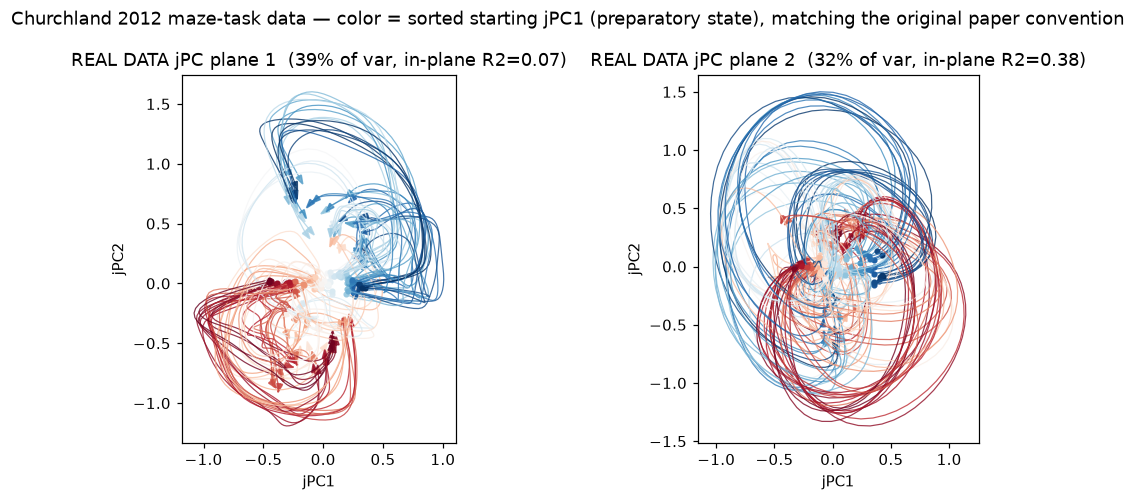

In [6]:
# --- Our pipeline on the real data (res from the jpca() call above) ----------
print('whole-space skew-symmetric fit R^2 = %.3f' % res['r2'])
print('plane frequencies (Hz):', np.round(res['freqs_hz'], 2))
projs = project_planes(res)
for k, (_, frac, r2p) in enumerate(projs, 1):
    print('jPC plane %d: %4.1f%% of variance | in-plane rotation R^2 = %+.2f | %.2f Hz'
          % (k, 100 * frac, r2p, res['freqs_hz'][k - 1]))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, (coords, frac, r2p), k in zip(axes, projs, [1, 2]):
    cols_k = start_ordered_colors(coords)      # color = starting jPC1 (preparatory)
    hw = 0.03 * np.abs(coords).max()
    for c in range(C):
        ax.plot(coords[0, c], coords[1, c], color=cols_k[c], lw=0.8, alpha=0.8)
        ax.plot(coords[0, c, 0], coords[1, c, 0], 'o', color=cols_k[c], ms=3)
        ax.arrow(coords[0, c, -1], coords[1, c, -1],
                 coords[0, c, -1] - coords[0, c, -2],
                 coords[1, c, -1] - coords[1, c, -2],
                 color=cols_k[c], alpha=0.8, head_width=hw, length_includes_head=True)
    ax.set_title(f'REAL DATA jPC plane {k}  ({frac:.0%} of var, in-plane R2={r2p:.2f})')
    ax.set_xlabel('jPC1'); ax.set_ylabel('jPC2'); ax.set_aspect('equal')
fig.suptitle('Churchland 2012 maze-task data — color = sorted starting jPC1 '
             '(preparatory state), matching the original paper convention')
fig.tight_layout(); plt.show()

## Same data, different lens: PCA vs jPCA

The classic 8-target "starburst" figures in the reaching literature are plain **PCA**
projections — axes that maximize variance. jPCA uses the *same* data and the *same*
initial PCA reduction, then re-rotates within that 6-D PC space so the axes align with
rotational dynamics instead of variance. Both views below come from the identical
preprocessed rates (`rates_p`): the left panel is simply the top two PCs
(`res['Z'][:2]`), the right is jPC plane 1.

Watch what changes: in the variance view, conditions spread apart (condition identity
dominates variance — the "spokes" / initial states). In the dynamics view, the same
trajectories wind into nested loops rotating in a common direction. As the 2012 paper
puts it, the rotations *"were always present in the top PCs, but were difficult to see
because they were not axis aligned."*

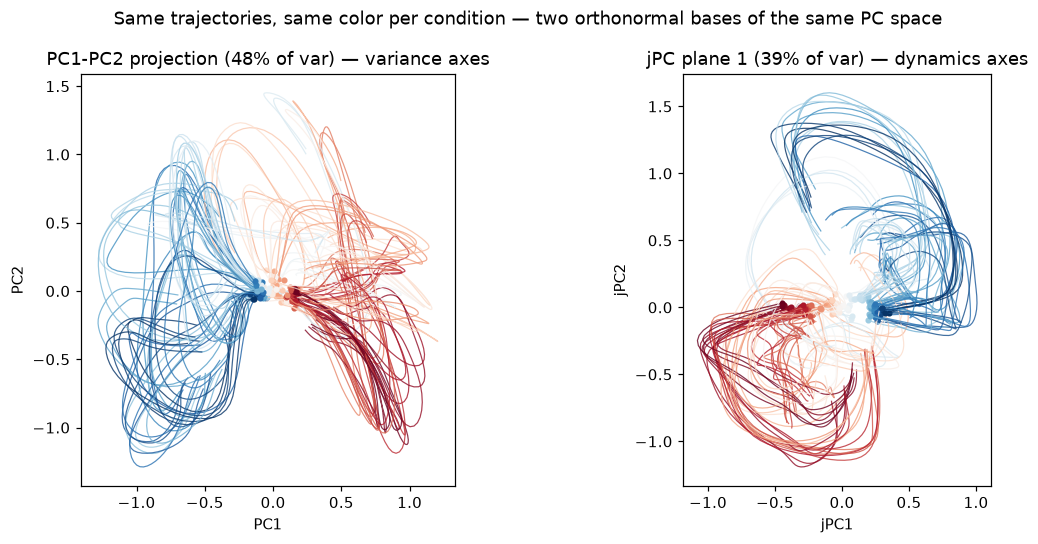

In [7]:
# --- PCA (variance axes) vs jPCA (dynamics axes), same data -----------------
pc_coords = unstack(res['Z'][:2], C)             # top-2 PC projection, (2, C, T)
pc_frac = np.sum(res['Z'][:2] ** 2) / np.sum(res['Z'] ** 2)
cols0 = start_ordered_colors(projs[0][0])  # one condition->color map for both panels

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for c in range(C):
    axes[0].plot(pc_coords[0, c], pc_coords[1, c], color=cols0[c], lw=0.8, alpha=0.8)
    axes[0].plot(pc_coords[0, c, 0], pc_coords[1, c, 0], 'o', color=cols0[c], ms=3)
axes[0].set_title(f'PC1-PC2 projection ({pc_frac:.0%} of var) — variance axes')
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2'); axes[0].set_aspect('equal')

coords, frac, r2p = projs[0]
for c in range(C):
    axes[1].plot(coords[0, c], coords[1, c], color=cols0[c], lw=0.8, alpha=0.8)
    axes[1].plot(coords[0, c, 0], coords[1, c, 0], 'o', color=cols0[c], ms=3)
axes[1].set_title(f'jPC plane 1 ({frac:.0%} of var) — dynamics axes')
axes[1].set_xlabel('jPC1'); axes[1].set_ylabel('jPC2'); axes[1].set_aspect('equal')

fig.suptitle('Same trajectories, same color per condition — two orthonormal bases of the same PC space')
fig.tight_layout(); plt.show()

## Why doesn't our figure look exactly like the paper's Figure 3?

Two reasons remain, in order of visual impact:

1. **Time window.** The paper plots only the **first 200 ms of movement-related
   activity** per condition; everything above used the full 600 ms supplied in the
   file, so each loop includes the movement-offset / return segment, which doubles
   back and tangles the picture. Below we refit jPCA on just −50 to 150 ms — the
   arcs immediately resolve into the sweeping, radiating structure of the paper's
   panels.
2. **Which dataset.** The clean textbook loops are Figure 3a–b: monkeys B and A,
   28 *straight-reach* conditions recorded with single electrodes. This file is the
   108-condition **array** dataset (curved + straight reaches mixed), whose paper
   panels (e–f) are visibly messier too.

Three further conventions of the original pipeline are now adopted here, after a
side-by-side comparison with the reference Python port (`bantin/jPCA`,
`simple_jPCA_example.ipynb`). Both are the **default** in our `jpca()`, so all
three notebooks follow the original paper's analysis:

- **Axis alignment** (`align_axes`, on by default). The basis *within* a jPC
  plane is arbitrary up to rotation, and the toolbox rotates it so the
  first-bin — preparatory — states lie along the jPC1 axis. Without this step
  the preparatory cloud leaks into both axes: across conditions, the
  trial-start states have std 0.34 / 0.31 in jPC1 / jPC2 before alignment, vs
  0.45 / 0.05 after — the same cloud, just rotated. This, not the data, is
  what makes the paper's preparatory points look compact and ours did not.
- **Constrained skew fit** (`refine_skew`, on by default). The toolbox
  minimizes ‖dX − M·X‖ over skew-symmetric M directly (conjugate gradients);
  the closed-form `(M − Mᵀ)/2` shortcut is only its initialization. The
  difference is small (‖ΔM‖/‖M‖ ≈ 0.13 here) but this notebook matches the
  reference pipeline exactly.
- **Coloring.** Trajectories are colored by sorted starting jPC1 coordinate —
  the preparatory state — via `start_ordered_colors`, as in the paper and the
  MATLAB toolbox. Axes are still defined up to an overall sign.

Honest caveat: even in the paper's window, the in-plane skew-symmetric fit is
weak for this dataset — the rotation is visually consistent but the linear
model in that plane explains little. The paper's quantitative claim rests on
the fit in the full 6-D PC space, not on clean in-plane fits.

200 ms window: plane 1 46% of var | in-plane rotation R^2 = +0.01 | freqs [0.94 0.63 0.1 ] Hz


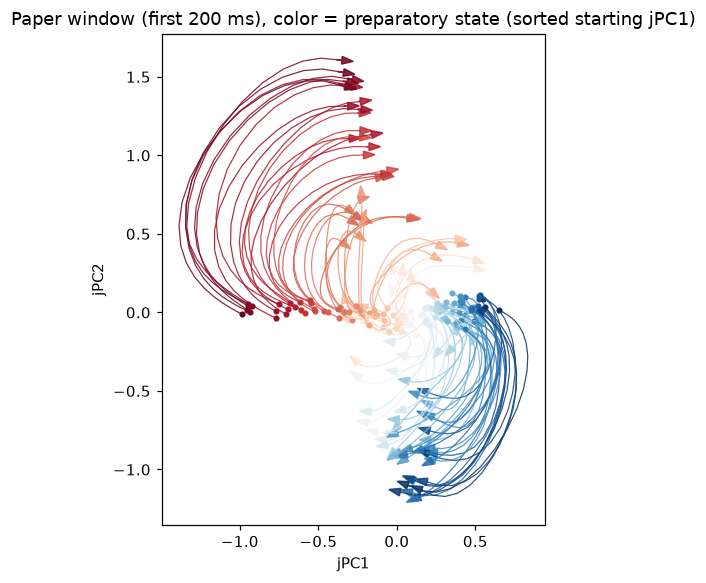

In [8]:
# --- Refit jPCA on the paper's analysis window (first 200 ms) ---------------
k200 = int(np.searchsorted(times, 150))          # -50 .. 150 ms
res200 = jpca(rates_p[:, :, :k200], n_pcs=6, dt_s=0.01)   # same default pipeline
coords200, frac200, r2p200 = project_planes(res200)[0]
print('200 ms window: plane 1 %.0f%% of var | in-plane rotation R^2 = %+.2f | freqs %s Hz'
      % (100 * frac200, r2p200, np.round(res200['freqs_hz'], 2)))

fig, ax = plt.subplots(figsize=(6, 5.4))
cols200 = start_ordered_colors(coords200)      # color = sorted starting jPC1
hw = 0.03 * np.abs(coords200).max()
for c in range(C):
    ax.plot(coords200[0, c], coords200[1, c], color=cols200[c], lw=0.8, alpha=0.85)
    ax.plot(coords200[0, c, 0], coords200[1, c, 0], 'o', color=cols200[c], ms=3)
    ax.arrow(coords200[0, c, -1], coords200[1, c, -1],
             coords200[0, c, -1] - coords200[0, c, -2],
             coords200[1, c, -1] - coords200[1, c, -2],
             color=cols200[c], alpha=0.85, head_width=hw, length_includes_head=True)
ax.set_title('Paper window (first 200 ms), color = preparatory state (sorted starting jPC1)')
ax.set_xlabel('jPC1'); ax.set_ylabel('jPC2'); ax.set_aspect('equal')
fig.tight_layout(); plt.show()

## Compare with the synthetic version

Put this figure next to Notebook 1's. The real data shows the same qualitative
structure — nested, consistently directed loops in the top planes — which is why the
synthetic generator in `simulate_reaching` was built the way it was. The differences
are equally instructive: the real trajectories are messier, the plane variance is split
less cleanly, and with 108 heterogeneous maze conditions the "radius per condition"
organization is only approximate.

Then ask the Lebedev/Kuzmina question of *this* dataset: the sorted raster above shows
the peak-time wave is already there in the raw rates. jPCA did not discover a hidden
engine — it re-displayed an order that exists in the data. Whether that order has a
physical, anatomical address is the question no electrode-only dataset can answer —
and the subject of the proposed experiments. → Notebook 2.